In [9]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [10]:
for f in fm.findSystemFonts():
    if "times" in f.lower():
        prop = fm.FontProperties(fname=f)
        print(f, " -> ", prop.get_name())

In [11]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [12]:
def block_freq_bootstrap(A,n_iterations,n_sample):
    length = len(A)
    A_nparr = A.values
    block_freqs = []
    for n in tqdm(range(n_iterations)):
        idxs = np.random.choice(np.arange(0,length,1),size=n_sample,replace=False)
        block_freqs.append(np.where(A_nparr[idxs]>0,1,0).mean(axis=0)*100)
    block_freq_das = []
    for element in block_freqs:
        block_freq_das.append(
            xr.DataArray(element, coords={'lat': A.lat, 'lon': A.lon}, dims=['lat', 'lon'])
        )
    block_freq_da = xr.concat(block_freq_das,dim = 'realization')
    return (block_freq_da.std('realization')*(np.sqrt(n_sample)/np.sqrt(len(A)))).rename('LWAA_freq_std')

In [13]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc')
        ds_input = xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})
        F1 = ds_input['F1'].mean('time')
        F1_std = (ds_input['F1'].std('time')/np.sqrt(2*365*50)).rename('F1_std')
        F2 = ds_input['F2'].mean('time')
        F2_std = (ds_input['F2'].std('time')/np.sqrt(2*365*50)).rename('F2_std')
        F3 = ds_input['F3'].mean('time')
        F3_std = (ds_input['F3'].std('time')/np.sqrt(2*365*50)).rename('F3_std')
        ds = xr.merge([F1,F2,F3,F1_std,F2_std,F3_std])
        ds.to_netcdf(f'{base_path}/{experiment}/lin_fluxes_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
        ds_input.close()

else:
    for i,experiment in enumerate(experiments):
        ds_fluxes = xr.open_dataset(f'{base_path}/{experiment}/lin_fluxes_CLIM_1.5x1.5.nc')
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')
        ds = xr.merge([ds, ds_fluxes])
        ds['CLIM_transient_flux_std'] = np.sqrt(ds['F1_std']**2 + ds['F2_std']**2 + ds['F3_std']**2)
        ds_clims.append(ds)

In [54]:
from scipy.ndimage import gaussian_filter

def gauss_smooth(da, sigma_deg=1):
    """Gaussian smoothing of a (..., lat, lon) DataArray.
    sigma_deg: std of the kernel in degrees. NaNs are handled by normalised convolution."""
    dlat = float(abs(da.lat[1] - da.lat[0]))
    dlon = float(abs(da.lon[1] - da.lon[0]))
    sig = (sigma_deg / dlat, sigma_deg / dlon)      # convert degrees -> grid points

    def _f(a):
        mask = np.isfinite(a)
        num = gaussian_filter(np.where(mask, a, 0.0), sig, mode=('nearest', 'wrap'))
        den = gaussian_filter(mask.astype(float), sig, mode=('nearest', 'wrap'))
        out = num / np.where(den > 1e-6, den, np.nan)
        return np.where(mask, out, np.nan)

    return xr.apply_ufunc(_f, da,
                          input_core_dims=[['lat', 'lon']],
                          output_core_dims=[['lat', 'lon']],
                          vectorize=True, keep_attrs=True)

In [55]:
# Load blocking data
ds_blocks = []

for i,experiment in enumerate(experiments):
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')
    ds_blocks.append(gauss_smooth(ds['LWAA_freq']).to_dataset())
    ds_blocks[-1]['LWAA_freq_std'] = block_freq_bootstrap(ds['LWAA_tracked'],50,1000)
    ds.close()

100%|███████████████████████████████████████████████████████████████████████| 50/50 [00:04<00:00, 11.95it/s]


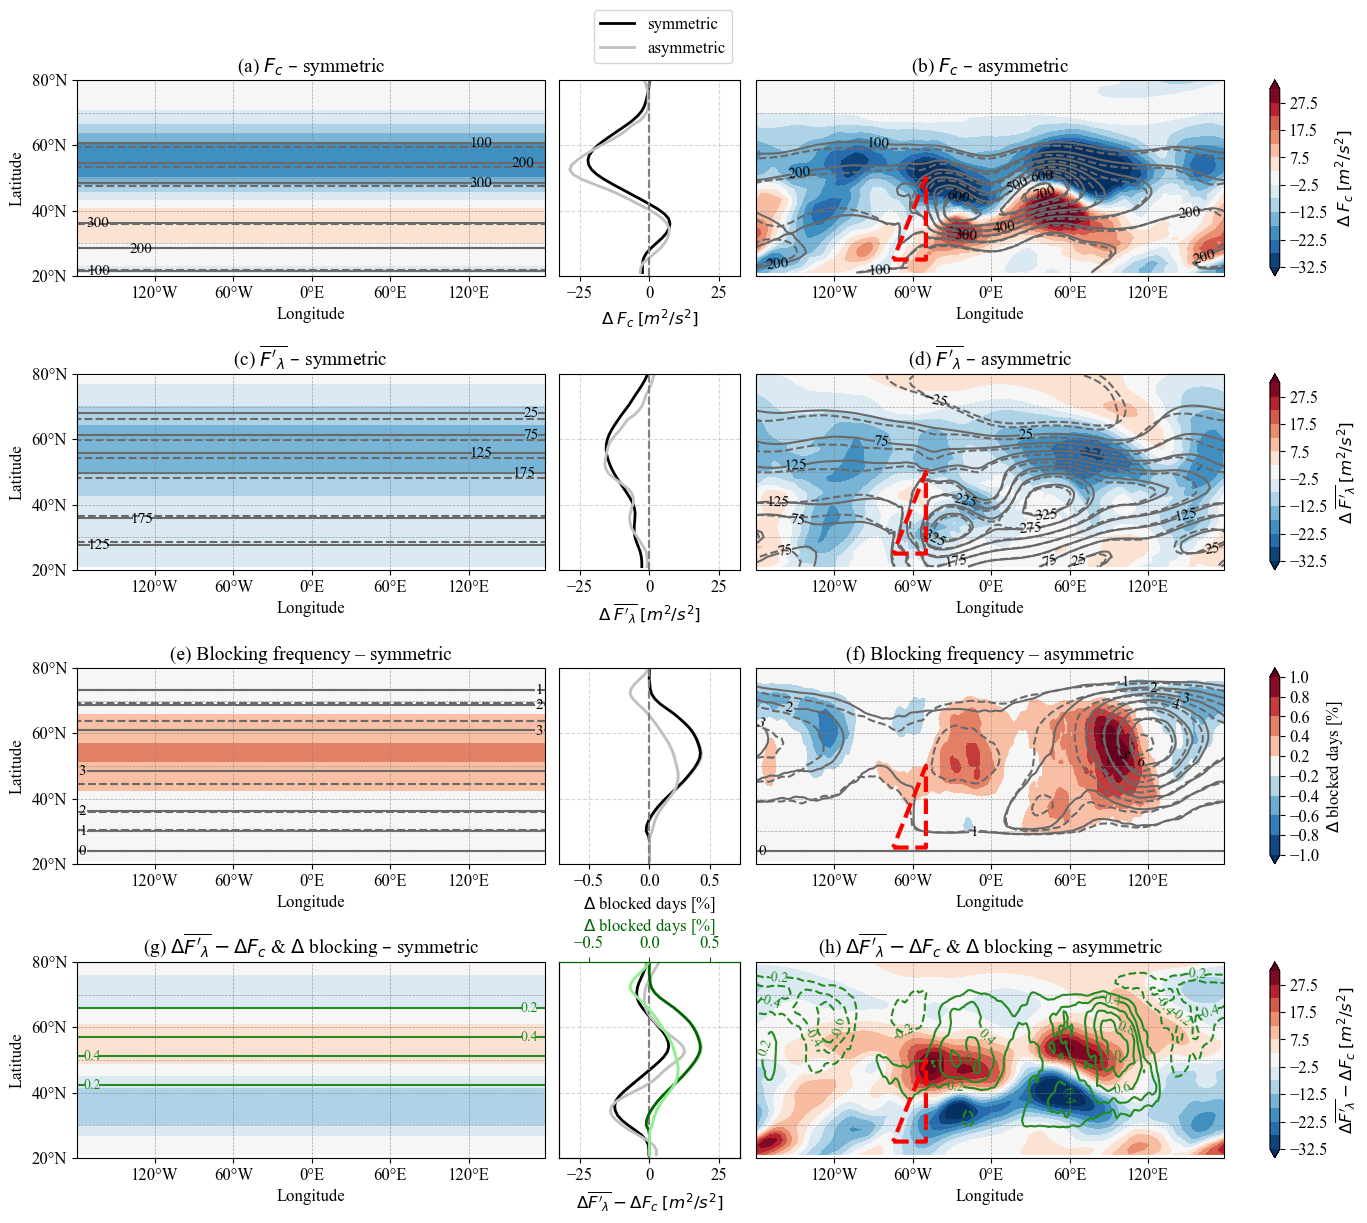

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs

plt.rcParams['font.size'] = 12
plt.rcParams['hatch.color'] = 'k'
plt.rcParams['hatch.linewidth'] = 0.6

# Assumes ds_clims, ds_blocks and DA_clims are already defined.

# --------------------------------------------------
# Settings to check
# --------------------------------------------------

LAT_MIN, LAT_MAX = 20, 80

def crop_lat(ds):
    """Keep only LAT_MIN-LAT_MAX, whatever the latitude ordering."""
    ascending = bool(ds.lat[0] < ds.lat[-1])
    sl = slice(LAT_MIN, LAT_MAX) if ascending else slice(LAT_MAX, LAT_MIN)
    return ds.sel(lat=sl)

ds_clims  = [crop_lat(d) for d in ds_clims]
ds_blocks = [crop_lat(d) for d in ds_blocks]

VAR_FLAMBDA       = 'FC'                        # FC (row 1) -- adjust to your dataset
VAR_FLAMBDA_PRIME = 'CLIM_transient_flux'  # F'_lambda (row 2)
VAR_BLOCK         = 'LWAA_freq'                 # blocking frequency (row 3); std in LWAA_freq_std

Z_SIG = 1.96    # 95% two-sided
N_EFF = 1       # if *_std is the interannual spread, use the number of years/members
                # (std of the mean = std/sqrt(N_EFF)); keep 1 if *_std already is
                # the uncertainty of the mean
HATCH = '...'   # drawn where the shaded difference is NOT significant

# ==================================================
# Figure layout
# ==================================================
fig = plt.figure(figsize=(20, 14))
gs = gridspec.GridSpec(
    nrows=4, ncols=5,
    width_ratios=[6.0, 0.25, 1.2, 0.01, 6.0],
    hspace=0.5, wspace=-0.3
)
"""
fig = plt.figure(figsize=(20, 13))
gs = gridspec.GridSpec(nrows=4, ncols=5,
                       width_ratios=[6.0, 0.37, 1.2, 0.01, 6.0],
                       hspace=0.6, wspace=-0.3)
"""
titles  = ['symmetric', 'asymmetric']
# left column: (a),(c),(e),(g); right column: (b),(d),(f),(h)
letters = ['(a)','(c)','(e)','(g)','(b)','(d)','(f)','(h)']
colors       = ['k', 'silver']               # shaded fields / zonal means: SYM, ASYM
green_zonal  = ['darkgreen', 'lightgreen']   # blocking difference zonal means: SYM, ASYM
green_map    = 'forestgreen'                 # blocking difference contours on the maps

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)
lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()

# --------------------------------------------------
# Helpers
# --------------------------------------------------
def style_map(ax_map, i):
    ax_map.set_aspect(2.5)
    ax_map.set_ylim(LAT_MIN,LAT_MAX)
    ax_map.set_xticks([-120,-60,0,60,120], crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i == 0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

def style_xsec(ax):
    ax.axvline(0, color='gray', ls='--')
    ax.set_ylim(LAT_MIN,LAT_MAX)
    ax.grid(True, ls='--', alpha=0.5)
    ax.tick_params(axis='y', length=0)
    plt.setp(ax.get_yticklabels(), visible=False)

def variance(std_da):
    """Variance of the climatological mean from the stored std."""
    return (std_da / np.sqrt(N_EFF))**2

def diff_sigma(variances, zonal, ref):
    """
    Std of a difference built from independent terms (list of variance DataArrays).
    Returns (sigma_map[lat,lon], sigma_xsec[lat]).
    Zonal mean: errors assumed independent between longitudes.
    """
    nlon = ref.sizes['lon']
    var = sum(variances).broadcast_like(ref)
    sig_x = np.sqrt(var.mean('lon') / nlon)
    sig_m = sig_x.broadcast_like(ref) if zonal else np.sqrt(var)
    return sig_m, sig_x

def add_hatch(ax, lon, lat, diff, sigma, hatch=HATCH):
    """Hatch where |diff| > Z_SIG*sigma (not significant). NaNs are not hatched."""
    nonsig = (np.abs(diff) > Z_SIG * sigma)
    mask = (nonsig & diff.notnull() & sigma.notnull()).astype(float).values
    if mask.any():
        ax.contourf(lon, lat, mask, levels=[0.5, 1.5], colors='none',
                    hatches=[hatch], transform=ccrs.PlateCarree())

def add_band(ax, lat, mean, sx, color):
    ax.fill_betweenx(lat, mean - Z_SIG*sx, mean + Z_SIG*sx,
                     color=color, alpha=0.25, lw=0)

# --------------------------------------------------
# Precompute mean/broadcast outside the loop
# --------------------------------------------------
ds_a_list = [ds_clims[0].mean('lon').broadcast_like(ds_clims[0]),
             ds_clims[2]]
ds_b_list = [ds_clims[1].mean('lon').broadcast_like(ds_clims[0]),
             ds_clims[3]]

da_a_block_list = [ds_blocks[0][VAR_BLOCK].mean('lon').broadcast_like(ds_clims[0]),
                   ds_blocks[2][VAR_BLOCK]]
da_b_block_list = [ds_blocks[1][VAR_BLOCK].mean('lon').broadcast_like(ds_clims[0]),
                   ds_blocks[3][VAR_BLOCK]]

# --------------------------------------------------
# Levels / limits
# --------------------------------------------------
levels_FC         = np.arange(100, 1300, 100)
levels_flux       = np.arange(-225, 1300, 50)
levels_flux_diff  = np.arange(-32.5, 33, 5)
xlim_flux         = [-32.5, 32.5]

levels_block       = np.arange(0, 12, 1)
levels_block_diff  = np.array([-1, -0.8, -0.6, -0.4, -0.2, 0.2, 0.4, 0.6, 0.8,1])
xlim_block         = [-0.75, 0.75]

levels_dd          = np.arange(-32.5, 33, 5)     # row 4 shading: dF'_lambda - dF_lambda
xlim_dd            = [-32.5, 32.5]
# row 4 contours: blocking difference (zero excluded; negative levels are dashed automatically)
levels_block_dcont = np.array([-1, -0.8, -0.6, -0.4, -0.2, 0.2, 0.4, 0.6, 0.8,1])

# --------------------------------------------------
# Loop over symmetric/asymmetric
# --------------------------------------------------
for i in range(2):

    XSEC_COL = 2
    MAP_COL = 0 if i==0 else 4
    zonal = (i == 0)

    ds_a = ds_a_list[i]
    ds_b = ds_b_list[i]
    #from scipy.ndimage import gaussian_filter
    da_a_block = da_a_block_list[i]
    da_b_block = da_b_block_list[i]
    lat = ds_a.lat.values

    # raw datasets (the std fields are taken from here)
    raw_a, raw_b = ds_clims[2*i], ds_clims[2*i+1]
    blk_a, blk_b = ds_blocks[2*i], ds_blocks[2*i+1]
    ref = ds_a[VAR_FLAMBDA]

    # variances of each term entering the differences
    v_f_a  = variance(raw_a[VAR_FLAMBDA + '_std'])
    v_f_b  = variance(raw_b[VAR_FLAMBDA + '_std'])
    v_fp_a = variance(raw_a[VAR_FLAMBDA_PRIME + '_std'])
    v_fp_b = variance(raw_b[VAR_FLAMBDA_PRIME + '_std'])
    v_bl_a = variance(blk_a[VAR_BLOCK + '_std'])
    v_bl_b = variance(blk_b[VAR_BLOCK + '_std'])

    sig_f,  sigx_f  = diff_sigma([v_f_a,  v_f_b],  zonal, ref)
    sig_fp, sigx_fp = diff_sigma([v_fp_a, v_fp_b], zonal, ref)
    sig_bl, sigx_bl = diff_sigma([v_bl_a, v_bl_b], zonal, ref)
    # row 4: (F'_b - F'_a) - (F_b - F_a); F' and F_c assumed independent
    # (add the covariance terms if they are correlated)
    sig_dd, sigx_dd = diff_sigma([v_f_a, v_f_b, v_fp_a, v_fp_b], zonal, ref)

    # ---------------- ROW 1 — F_lambda ----------------
    if i == 0:
        ax_xsec_f1 = fig.add_subplot(gs[0, XSEC_COL])
    ax_map = fig.add_subplot(gs[0, MAP_COL], projection=proj, sharey=ax_xsec_f1)

    ax_map.set_title(f"{letters[i*4]} " + r"$F_c$" + f" – {titles[i]}")

    c1 = ax_map.contour(ds_a.lon, ds_a.lat, ds_a[VAR_FLAMBDA], levels=levels_FC,
                        colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, ds_b[VAR_FLAMBDA], levels=levels_FC,
                   colors='dimgray', linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    flam_diff = ds_b[VAR_FLAMBDA] - ds_a[VAR_FLAMBDA]
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, flam_diff,
                         levels=levels_flux_diff, cmap='RdBu_r', extend='both')
    #add_hatch(ax_map, ds_a.lon, ds_a.lat, flam_diff, sig_f)

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r"$\Delta$ $F_c$ $[m^2/s^2]$")

    style_map(ax_map, i)

    xs = flam_diff.mean('lon').values
    ax_xsec_f1.plot(xs, lat, color=colors[i], lw=2, label=titles[i])
    add_band(ax_xsec_f1, lat, xs, sigx_f.values, colors[i])
    ax_xsec_f1.set_xlabel(r"$\Delta$ $F_c$ $[m^2/s^2]$")
    ax_xsec_f1.set_xlim(xlim_flux)
    ax_xsec_f1.legend(loc='upper right', bbox_to_anchor=(1.0, 1.4))
    style_xsec(ax_xsec_f1)

    # ---------------- ROW 2 — F'_lambda ----------------
    if i == 0:
        ax_xsec_f2 = fig.add_subplot(gs[1, XSEC_COL])
    ax_map = fig.add_subplot(gs[1, MAP_COL], projection=proj, sharey=ax_xsec_f2)

    ax_map.set_title(f"{letters[i*4+1]} " + r"$\overline{F'_{\lambda}}$" + f" – {titles[i]}")

    c1 = ax_map.contour(ds_a.lon, ds_a.lat, ds_a[VAR_FLAMBDA_PRIME], levels=levels_flux,
                        colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, ds_b[VAR_FLAMBDA_PRIME], levels=levels_flux,
                   colors='dimgray', linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    lwf_diff = ds_b[VAR_FLAMBDA_PRIME] - ds_a[VAR_FLAMBDA_PRIME]
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, lwf_diff,
                         levels=levels_flux_diff, cmap='RdBu_r', extend='both')
    #add_hatch(ax_map, ds_a.lon, ds_a.lat, lwf_diff, sig_fp)

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r"$\Delta$ $\overline{F'_{\lambda}}$ $[m^2/s^2]$")

    style_map(ax_map, i)

    xs = lwf_diff.mean('lon').values
    ax_xsec_f2.plot(xs, lat, color=colors[i], lw=2, label=titles[i])
    add_band(ax_xsec_f2, lat, xs, sigx_fp.values, colors[i])
    ax_xsec_f2.set_xlabel(r"$\Delta$ $\overline{F'_{\lambda}}$ $[m^2/s^2]$")
    ax_xsec_f2.set_xlim(xlim_flux)
    style_xsec(ax_xsec_f2)

    # ---------------- ROW 3 — BLOCKING ----------------
    if i == 0:
        ax_xsec_block = fig.add_subplot(gs[2, XSEC_COL])
    ax_map = fig.add_subplot(gs[2, MAP_COL], projection=proj, sharey=ax_xsec_block)

    ax_map.set_title(f'{letters[i*4+2]} Blocking frequency – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon, ds_a.lat, da_a_block, levels=levels_block,
                        colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, da_b_block, levels=levels_block,
                   colors='dimgray', linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    block_diff = da_b_block - da_a_block
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, block_diff,
                         levels=levels_block_diff, cmap='RdBu_r', extend='both')
    #add_hatch(ax_map, ds_a.lon, ds_a.lat, block_diff, sig_bl)

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta$ blocked days [%]')

    style_map(ax_map, i)

    xs_bl = block_diff.mean('lon').values
    ax_xsec_block.plot(xs_bl, lat, color=colors[i], lw=2, label=titles[i])
    add_band(ax_xsec_block, lat, xs_bl, sigx_bl.values, colors[i])
    ax_xsec_block.set_xlabel(r'$\Delta$ blocked days [%]')
    ax_xsec_block.set_xlim(xlim_block)
    style_xsec(ax_xsec_block)

    # ---------------- ROW 4 — (dF'_lambda - dF_lambda) & d(blocking) ----------------
    if i == 0:
        ax_xsec_dd = fig.add_subplot(gs[3, XSEC_COL])
        ax_xsec_dd_twin = ax_xsec_dd.twiny()     # top axis: blocking difference (green)
    ax_map = fig.add_subplot(gs[3, MAP_COL], projection=proj, sharey=ax_xsec_dd)

    ax_map.set_title(f"{letters[i*4+3]} " + r"$\Delta \overline{F'_{\lambda}} - \Delta F_c$"
                     + r" & $\Delta$ blocking" + f" – {titles[i]}")

    dd_diff = lwf_diff - flam_diff
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, dd_diff,
                         levels=levels_dd, cmap='RdBu_r', extend='both')
    #add_hatch(ax_map, ds_a.lon, ds_a.lat, dd_diff, sig_dd)

    cg = ax_map.contour(ds_a.lon, ds_a.lat, block_diff, levels=levels_block_dcont,
                        colors=green_map, linewidths=1.5)
    ax_map.clabel(cg, inline=True, colors=green_map, fmt='%.1f', fontsize=10)

    if i > 0:
        fig.colorbar(sh, ax=ax_map, label=r"$\Delta \overline{F'_{\lambda}} - \Delta F_c$ $[m^2/s^2]$")

    style_map(ax_map, i)

    # zonal means: shaded field (bottom axis, black/silver), blocking difference (top axis, greens)
    xs_dd = dd_diff.mean('lon').values
    ax_xsec_dd.plot(xs_dd, lat, color=colors[i], lw=2, label=titles[i])
    add_band(ax_xsec_dd, lat, xs_dd, sigx_dd.values, colors[i])

    ax_xsec_dd_twin.plot(xs_bl, lat, color=green_zonal[i], lw=2)
    add_band(ax_xsec_dd_twin, lat, xs_bl, sigx_bl.values, green_zonal[i])

    ax_xsec_dd.set_xlabel(r"$\Delta \overline{F'_{\lambda}} - \Delta F_c$ $[m^2/s^2]$")
    ax_xsec_dd.set_xlim(xlim_dd)
    style_xsec(ax_xsec_dd)

    ax_xsec_dd_twin.set_xlim(xlim_block)
    ax_xsec_dd_twin.set_xlabel(r'$\Delta$ blocked days [%]', color='darkgreen')
    ax_xsec_dd_twin.tick_params(axis='x', labelcolor='darkgreen', color='darkgreen')
    ax_xsec_dd_twin.spines['top'].set_color('darkgreen')

# --------------------------------------------------
plt.savefig('PLOTS/Figure_5.png', dpi=200, bbox_inches='tight')  # faster for testing
plt.show()